In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import nltk

nltk.download('stopwords')
from nltk.corpus import stopwords as stopwords_scratch

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
from google.colab import files
files.upload()

{}

In [ ]:
data = pd.read_csv('rupiah_clean.csv')
data

,full_text
0,nilai tukar rupiah hari ini kamis oktober te...
1,jujur memang capek liat berita di indonesia hi...
2,anak usaha astra international di sektor perke...
3,nilai tukar dolar amerika serikat terhadap rup...
4,nilai tukar rupiah hari ini kamis oktober me...
...,...
994,baca di sini \n\nbank indonesia bi akan mempe...
995,gue lebih percaya thomaskong beneran pacaran d...
996,informasi kurs jisdor referensi kursnilai tuka...
997,investor asing masih terus melakukan aksi jual...


In [ ]:
# panggil stopword id
list_stopwords = stopwords_scratch.words('indonesian')
# panggil stopword en
list_stopwords_en = stopwords_scratch.words('english')
# gabungkan id & en
list_stopwords.extend(list_stopwords_en)
# tambah daftar stopword jika perlu
list_stopwords.extend(['ya', 'yg', 'ga', 'yuk', 'dah', 'ngga', 'engga', 'ygy'])
stopwords = list_stopwords

In [ ]:
data = data.fillna("").astype(str)
data = data.full_text.to_list()
data

['nilai tukar rupiah hari ini kamis  oktober  terkikis lagi\n\n     \n\n',
 'jujur memang capek liat berita di indonesia hiburan dikit keinget nilai rupiah lemah dan harga barang pada naik sekarang ada berita war antar rezim semoga perang kerakusan akan kekuasaan ini bisa menghibur rakyat menengah please lah bertarung sampai urat leher kalian tegang',
 'anak usaha astra international di sektor perkebunan sawit astra agro lestari aali umumkan  dividen interim tahun aali tebar dividen  miliar rupiah nilai dividen  rupiah per saham pemegang saham berhak terima dividen yang namanya tercatat di daftar  oktober  ',
 'nilai tukar dolar amerika serikat terhadap rupiah berada di kisaran rp per  dolar as pada perdagangan kamis  oktober  posisi tersebut menunjukkan rupiah masih berada dalam tekanan terhadap mata uang negeri paman sam\n\n',
 'nilai tukar rupiah hari ini kamis  oktober  melemah jadi rp per dolar as dolar as ',
 '  hai alvi kami mengapresiasi laporan dari masyarakat rupiah merupakan

In [ ]:
vectorizer = TfidfVectorizer(
    stop_words=stopwords,
    token_pattern=r"(?u)\b\w[\w-]*\w\b|\b\w\b",
)
X = vectorizer.fit_transform(data)

In [ ]:
range_n_clusters = [2, 3, 4, 5, 6, 7, 8, 9]
silhouette_avg_scores = []

for n_clusters in range_n_clusters:
    # Initialize KMeans
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
    cluster_labels = kmeans.fit_predict(X)

    # Calculate score
    score = silhouette_score(X, cluster_labels)
    silhouette_avg_scores.append(score)
    print(f"For n_clusters = {n_clusters}, Silhouette Score: {score:.4f}")

For n_clusters = 2, Silhouette Score: 0.0136
For n_clusters = 3, Silhouette Score: 0.0216
For n_clusters = 4, Silhouette Score: 0.0216
For n_clusters = 5, Silhouette Score: 0.0479
For n_clusters = 6, Silhouette Score: 0.0471
For n_clusters = 7, Silhouette Score: 0.0470
For n_clusters = 8, Silhouette Score: 0.0470
For n_clusters = 9, Silhouette Score: 0.0479


In [ ]:
true_k = 5
model = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)
model.fit(X)

KMeans(max_iter=100, n_clusters=5, n_init=1)

In [ ]:
order_centroids = model.cluster_centers_.argsort()[:, ::-1]
# get_feature_names is deprecated in scikit-learn versions >= 0.2
# and replaced by get_feature_names_out
terms = vectorizer.get_feature_names_out()

for i in range(true_k):
    print("Cluster %d:" % i),
    for ind in order_centroids[i, :10]:
        print(' %s' % terms[ind])
    print()

Cluster 0:
 nilai
 rupiah
 uang
 aja
 gak
 nya
 kalo
 mata
 gaji
 orang

Cluster 1:
 bi
 bank
 gubernur
 indonesia
 stabilitas
 menjaga
 rupiah
 kebijakan
 tukar
 nilai

Cluster 2:
 dolar
 rp
 perdagangan
 level
 rupiah
 tukar
 amerika
 serikat
 nilai
 melemah

Cluster 3:
 kurs
 kursnilai
 referensi
 informasi
 jisdor
 usdidr
 selengkapnya
 spot
 rp
 tukar

Cluster 4:
 nilai
 rupiah
 tukar
 harga
 indonesia
 rp
 ekonomi
 pasar
 ihsg
 melemah



In [ ]:
from sklearn.metrics import silhouette_score

silhouette_score(X, labels=model.predict(X))

# The best value is 1 and the worst value is -1. Values near 0 indicate overlapping clusters.
# Negative values generally indicate that a sample has been assigned to the wrong cluster, as a different cluster is more similar.

np.float64(0.0481112969699567)

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# reduce the features to 2D
pca = PCA(n_components=2, random_state=0)
reduced_features = pca.fit_transform(X.toarray())

# reduce the cluster centers to 2D
reduced_cluster_centers = pca.transform(model.cluster_centers_)

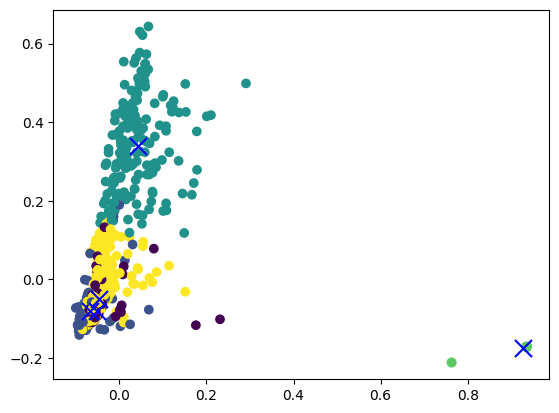

In [ ]:
plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=model.predict(X))
plt.scatter(reduced_cluster_centers[:, 0], reduced_cluster_centers[:, 1], marker='x', s=150, c='b')